## Change in Courier Delivery Behavior across Work Experience (Flag 4)

### Dataset Overview
The main table contains two workdays of order locations, receipt-event fields, and delivery-completion events for one courier. The secondary table contains GPS trajectories for the same two workdays in a shared derived coordinate frame.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Investigate how the courier's delivery behavior differs between the first observed workday and a recent workday.

Role: Last-mile delivery operations analyst


Category: Courier and Order Insight

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the relationship between current position and next completed destination differ between the courier's first and recent workdays?

#### Analysis action

Compare numbered completion order with the spatial positions of the remaining destinations on each day.

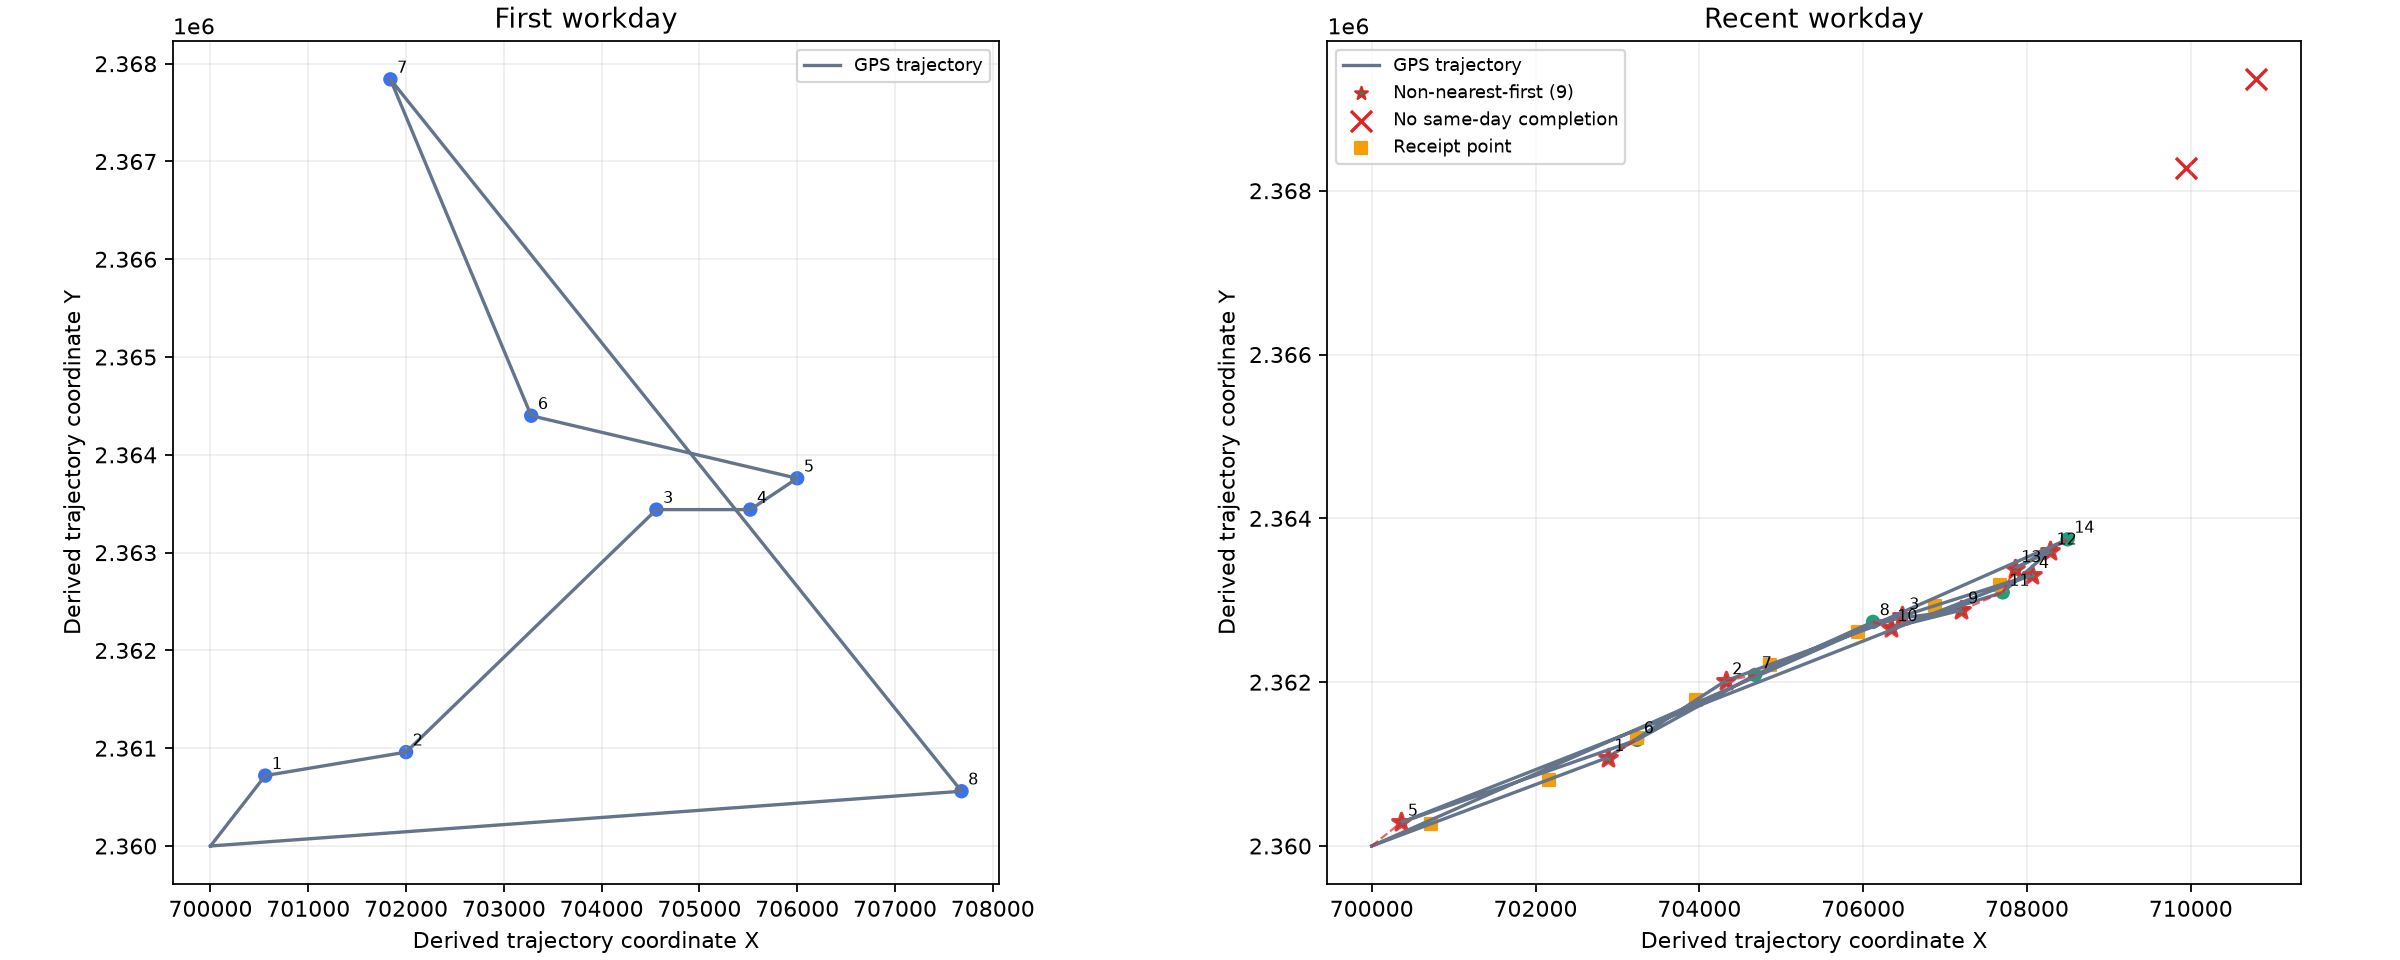

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
d['sign_time'] = pd.to_datetime(d['sign_time'])
t = user_df.copy()
t['gps_time'] = pd.to_datetime(t['gps_time'])
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, ds, title in zip(axes, sorted(d['ds'].dropna().unique()), ['First workday', 'Recent workday']):
 q = d[(d['ds'] == ds) & d['sign_time'].notna()].sort_values('sign_time')
 tr = t[t['ds'] == ds].sort_values('gps_time')
 ax.plot(tr['lng'], tr['lat'], color='gray', label='GPS trajectory')
 ax.scatter(q['poi_lng'], q['poi_lat'], c='tab:blue' if ds == sorted(d['ds'].dropna().unique())[0] else 'tab:green')
 for i, row in enumerate(q.itertuples(), 1): ax.annotate(str(i), (row.poi_lng, row.poi_lat))
 ax.set_title(title); ax.set_xlabel('Coordinate X'); ax.set_ylabel('Coordinate Y'); ax.axis('equal')
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/first_vs_recent_route_maps.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "On the first workday, the courier usually completes the destination nearest to the current position next. On the recent workday, the sequence is less consistently nearest-first: several farther destinations are completed while nearer destinations remain unfinished.",
  "insight_value": {
    "first_day_non_nearest_choices": 0,
    "recent_day_non_nearest_choices": 9,
    "recent_day_has_multiple_non_nearest_choices": true
  },
  "plot": {
    "plot_type": "two_panel_trajectory_map",
    "title": "First-Day and Recent-Day Delivery Sequences",
    "file": "visualizations/first_vs_recent_route_maps.png",
    "description": "Two panels compare GPS routes and numbered completion order. Red-edged stars mark recent-day choices that were not the nearest remaining destination; dashed red segments point to nearer unfinished alternatives."
  },
  "question": "How does the relationship between current position and next completed destination differ between the courier's first and recent workdays?",
  "actionable_insight": "Compare numbered completion order with the spatial positions of the remaining destinations on each day.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy()\nd['sign_time'] = pd.to_datetime(d['sign_time'])\nt = user_df.copy()\nt['gps_time'] = pd.to_datetime(t['gps_time'])\nfig, axes = plt.subplots(1, 2, figsize=(14, 6))\nfor ax, ds, title in zip(axes, sorted(d['ds'].dropna().unique()), ['First workday', 'Recent workday']):\n q = d[(d['ds'] == ds) & d['sign_time'].notna()].sort_values('sign_time')\n tr = t[t['ds'] == ds].sort_values('gps_time')\n ax.plot(tr['lng'], tr['lat'], color='gray', label='GPS trajectory')\n ax.scatter(q['poi_lng'], q['poi_lat'], c='tab:blue' if ds == sorted(d['ds'].dropna().unique())[0] else 'tab:green')\n for i, row in enumerate(q.itertuples(), 1): ax.annotate(str(i), (row.poi_lng, row.poi_lat))\n ax.set_title(title); ax.set_xlabel('Coordinate X'); ax.set_ylabel('Coordinate Y'); ax.axis('equal')\nplt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "completion_time",
    "destination_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 2**: How does the trajectory distance traveled per completed order differ between the first and recent workdays, and does nearest-first behavior imply a shorter overall route?

#### Analysis action

Compare per-order trajectory segments and the total route structure rather than equating nearest-first completion with global route efficiency.

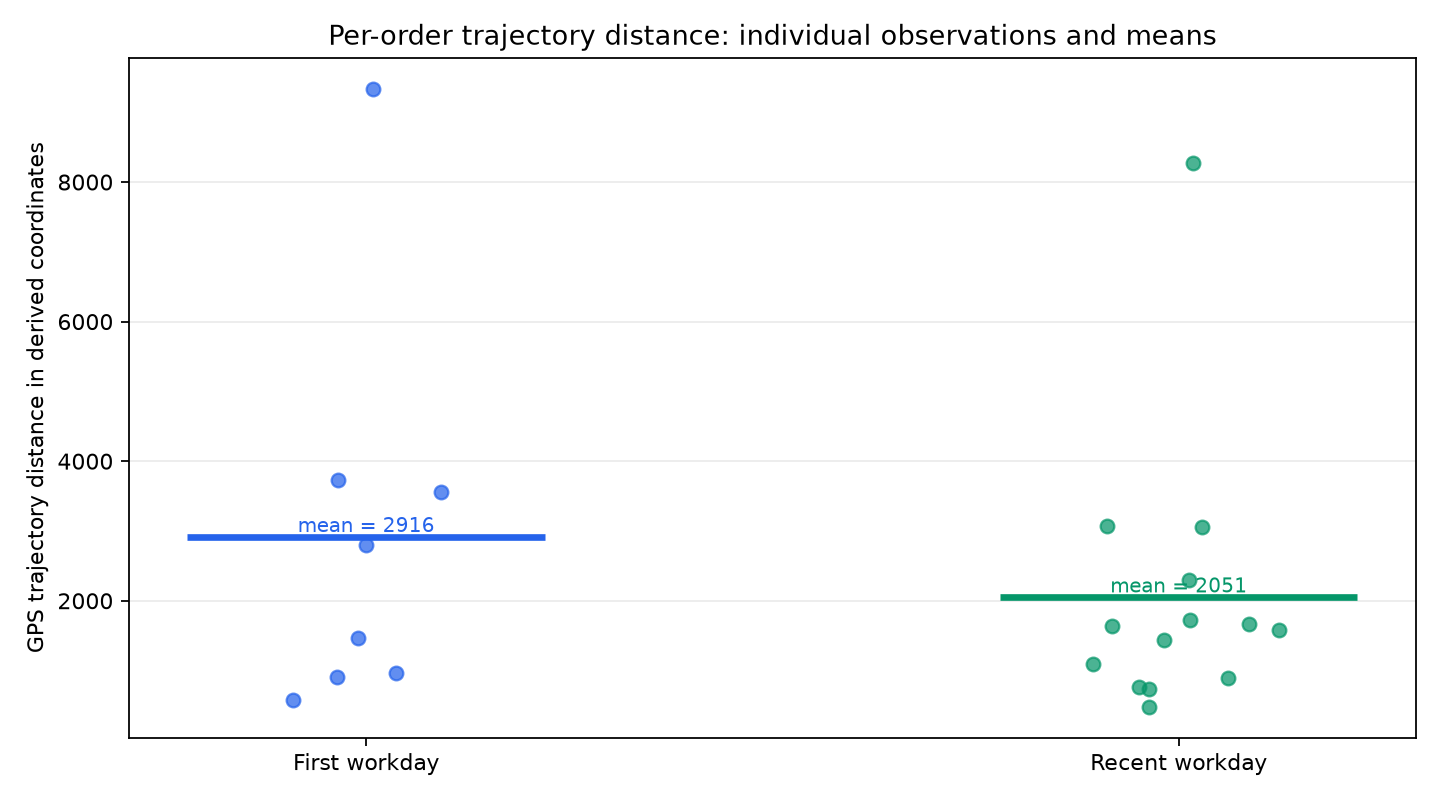

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

d = df.copy(); d['sign_time'] = pd.to_datetime(d['sign_time']); t = user_df.copy(); t['gps_time'] = pd.to_datetime(t['gps_time'])
values = []
for ds, q in d[d['sign_time'].notna()].groupby('ds'):
 q = q.sort_values('sign_time'); tr = t[t['ds'] == ds].sort_values('gps_time'); previous_time = tr['gps_time'].min()
 for _, row in q.iterrows():
 segment = tr[(tr['gps_time'] > previous_time) & (tr['gps_time'] <= row['sign_time'])]
 segment = pd.concat([tr[tr['gps_time'] == previous_time].tail(1), segment]) if len(segment) else segment
 values.append({'ds': ds, 'distance': np.hypot(np.diff(segment['lng']), np.diff(segment['lat'])).sum() if len(segment) > 1 else 0}); previous_time = row['sign_time']
summary = pd.DataFrame(values); fig, ax = plt.subplots(figsize=(9,5))
for xpos, (ds, q) in enumerate(summary.groupby('ds')):
 ax.scatter(np.full(len(q), xpos) + np.random.default_rng(xpos).normal(0,.05,len(q)), q['distance'], alpha=.7); ax.hlines(q['distance'].mean(), xpos-.2, xpos+.2, linewidth=3)
ax.set_xticks(range(summary['ds'].nunique()), ['First workday','Recent workday']); ax.set_ylabel('GPS trajectory distance'); ax.set_title('Per-order distance observations and means'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/per_order_distance_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "The recent workday has a lower mean GPS trajectory distance per completed order than the first workday. The first-day nearest-first strategy still produces a longer overall route than the more compact recent-day route.",
  "insight_value": {
    "metric": "trajectory distance per completed order",
    "recent_lower_than_first": true,
    "first_day_greedy_route_not_shortest": true
  },
  "plot": {
    "plot_type": "per_order_distance_dotplot",
    "title": "Per-Order Trajectory Distance: Individual Observations and Means",
    "file": "visualizations/per_order_distance_comparison.png",
    "description": "Each point is one completed order's assigned trajectory distance; horizontal lines show the mean for each workday."
  },
  "question": "How does the trajectory distance traveled per completed order differ between the first and recent workdays, and does nearest-first behavior imply a shorter overall route?",
  "actionable_insight": "Compare per-order trajectory segments and the total route structure rather than equating nearest-first completion with global route efficiency.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\nd = df.copy(); d['sign_time'] = pd.to_datetime(d['sign_time']); t = user_df.copy(); t['gps_time'] = pd.to_datetime(t['gps_time'])\nvalues = []\nfor ds, q in d[d['sign_time'].notna()].groupby('ds'):\n q = q.sort_values('sign_time'); tr = t[t['ds'] == ds].sort_values('gps_time'); previous_time = tr['gps_time'].min()\n for _, row in q.iterrows():\n segment = tr[(tr['gps_time'] > previous_time) & (tr['gps_time'] <= row['sign_time'])]\n segment = pd.concat([tr[tr['gps_time'] == previous_time].tail(1), segment]) if len(segment) else segment\n values.append({'ds': ds, 'distance': np.hypot(np.diff(segment['lng']), np.diff(segment['lat'])).sum() if len(segment) > 1 else 0}); previous_time = row['sign_time']\nsummary = pd.DataFrame(values); fig, ax = plt.subplots(figsize=(9,5))\nfor xpos, (ds, q) in enumerate(summary.groupby('ds')):\n ax.scatter(np.full(len(q), xpos) + np.random.default_rng(xpos).normal(0,.05,len(q)), q['distance'], alpha=.7); ax.hlines(q['distance'].mean(), xpos-.2, xpos+.2, linewidth=3)\nax.set_xticks(range(summary['ds'].nunique()), ['First workday','Recent workday']); ax.set_ylabel('GPS trajectory distance'); ax.set_title('Per-order distance observations and means'); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 3**: How does the courier's mean movement speed differ between the first and recent workdays?

#### Analysis action

Compare the movement-speed summaries by date together with the route maps and per-order distances.

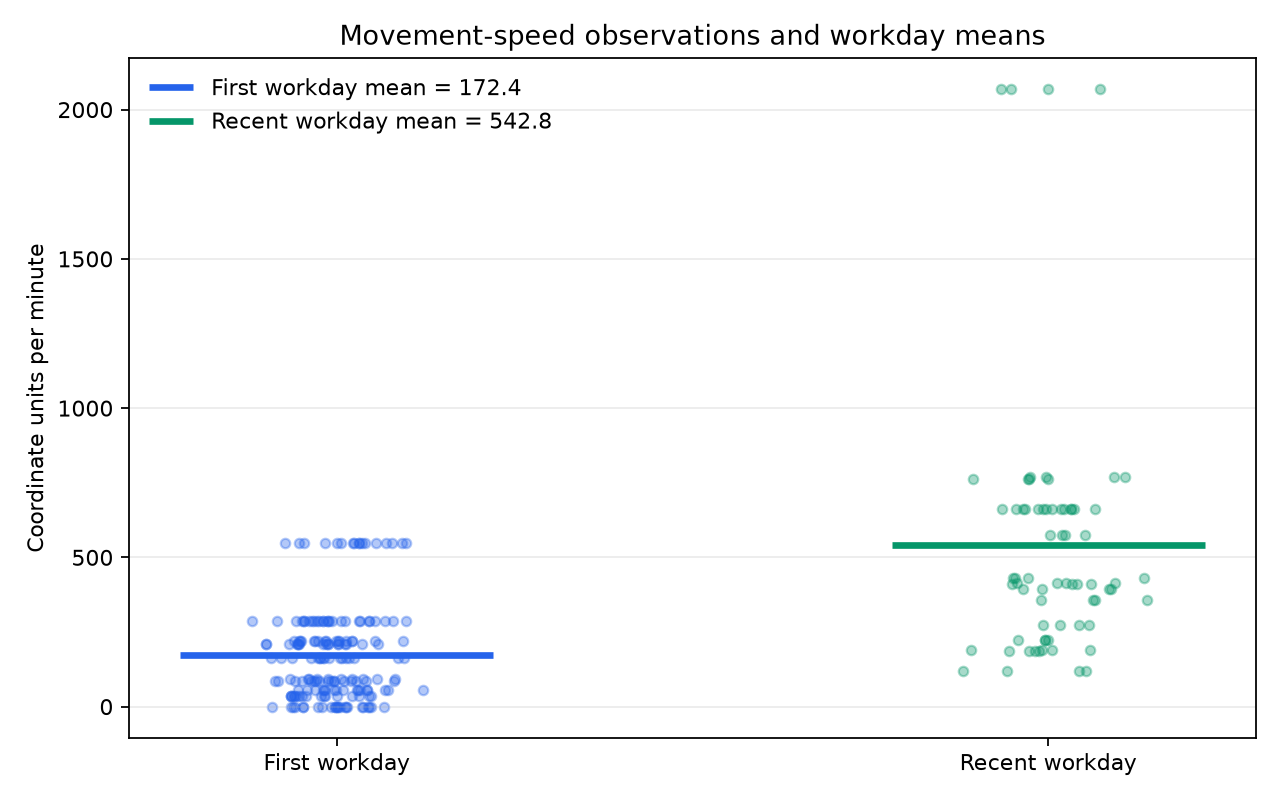

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
t = user_df.copy(); t['gps_time'] = pd.to_datetime(t['gps_time']); t = t.sort_values(['ds','gps_time']); t['speed'] = np.hypot(t.groupby('ds')['lng'].diff(), t.groupby('ds')['lat'].diff()) / (t.groupby('ds')['gps_time'].diff().dt.total_seconds()/60)
fig, ax = plt.subplots(figsize=(8,5))
for xpos, (ds, q) in enumerate(t.dropna(subset=['speed']).groupby('ds')):
 ax.scatter(np.full(len(q), xpos)+np.random.default_rng(xpos).normal(0,.05,len(q)), q['speed'], alpha=.35); ax.hlines(q['speed'].mean(), xpos-.2, xpos+.2, linewidth=3)
ax.set_xticks([0,1], ['First workday','Recent workday']); ax.set_ylabel('Coordinate units per minute'); ax.set_title('Movement-speed observations and means'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "The courier's mean GPS movement speed is higher on the recent workday than on the first workday.",
  "insight_value": {
    "metric": "mean GPS movement speed",
    "recent_higher_than_first": true
  },
  "plot": {
    "plot_type": "speed_strip_with_means",
    "title": "Movement-Speed Observations and Workday Means",
    "file": "visualizations/speed_comparison.png",
    "description": "Individual GPS segment speeds are shown as jittered points, with a horizontal mean line for each workday."
  },
  "question": "How does the courier's mean movement speed differ between the first and recent workdays?",
  "actionable_insight": "Compare the movement-speed summaries by date together with the route maps and per-order distances.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nt = user_df.copy(); t['gps_time'] = pd.to_datetime(t['gps_time']); t = t.sort_values(['ds','gps_time']); t['speed'] = np.hypot(t.groupby('ds')['lng'].diff(), t.groupby('ds')['lat'].diff()) / (t.groupby('ds')['gps_time'].diff().dt.total_seconds()/60)\nfig, ax = plt.subplots(figsize=(8,5))\nfor xpos, (ds, q) in enumerate(t.dropna(subset=['speed']).groupby('ds')):\n ax.scatter(np.full(len(q), xpos)+np.random.default_rng(xpos).normal(0,.05,len(q)), q['speed'], alpha=.35); ax.hlines(q['speed'].mean(), xpos-.2, xpos+.2, linewidth=3)\nax.set_xticks([0,1], ['First workday','Recent workday']); ax.set_ylabel('Coordinate units per minute'); ax.set_title('Movement-speed observations and means'); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position"
  ]
}

### **Question 4**: How does the share of orders with observed receipt events differ between the first and recent workdays?

#### Analysis action

Compare missing and observed receipt-event fields by date before interpreting changes in the courier's work pattern.

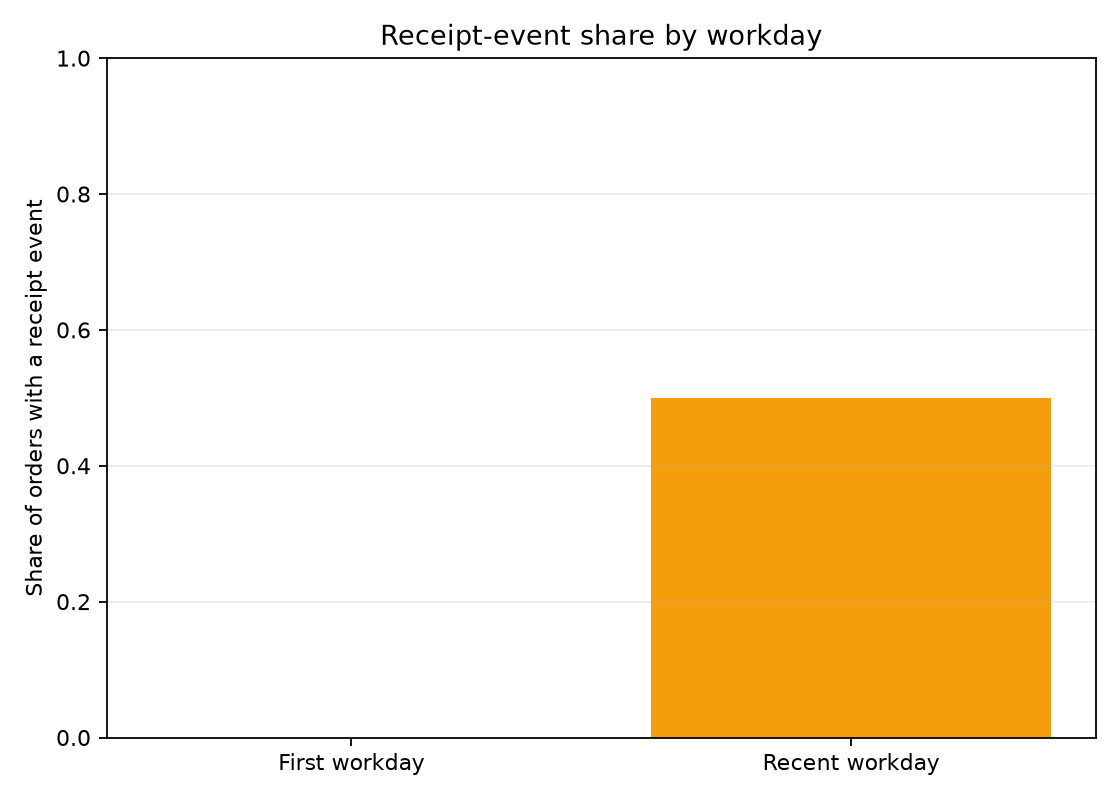

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); d['has_receipt'] = d['receipt_time'].notna() & d['receipt_lng'].notna()
share = d.groupby('ds')['has_receipt'].mean()
share.plot(kind='bar', color=['#94a3b8', '#f59e0b'])
plt.ylim(0, 1); plt.ylabel('Share of orders with receipt event'); plt.title('Receipt-event share by workday'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/receipt_share_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "No receipt events are present on the first workday, whereas receipt events are present for half of the recent-workday orders.",
  "insight_value": {
    "first_day_receipt_share": 0.0,
    "recent_day_receipt_share": 0.5
  },
  "plot": {
    "plot_type": "bar_chart",
    "title": "Receipt-Event Share by Workday",
    "file": "visualizations/receipt_share_comparison.png",
    "description": "The share of order rows with non-missing receipt time and receipt coordinates is compared across the two dates."
  },
  "question": "How does the share of orders with observed receipt events differ between the first and recent workdays?",
  "actionable_insight": "Compare missing and observed receipt-event fields by date before interpreting changes in the courier's work pattern.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); d['has_receipt'] = d['receipt_time'].notna() & d['receipt_lng'].notna()\nshare = d.groupby('ds')['has_receipt'].mean()\nshare.plot(kind='bar', color=['#94a3b8', '#f59e0b'])\nplt.ylim(0, 1); plt.ylabel('Share of orders with receipt event'); plt.title('Receipt-event share by workday'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "completion_time",
    "task_id"
  ]
}

### **Question 5**: Among recent-day orders with receipt events, are there far destinations that lack same-day completion and matching trajectory evidence?

#### Analysis action

Compare receipt-bearing orders with missing completion events and inspect whether their destinations fall outside the observed day route.

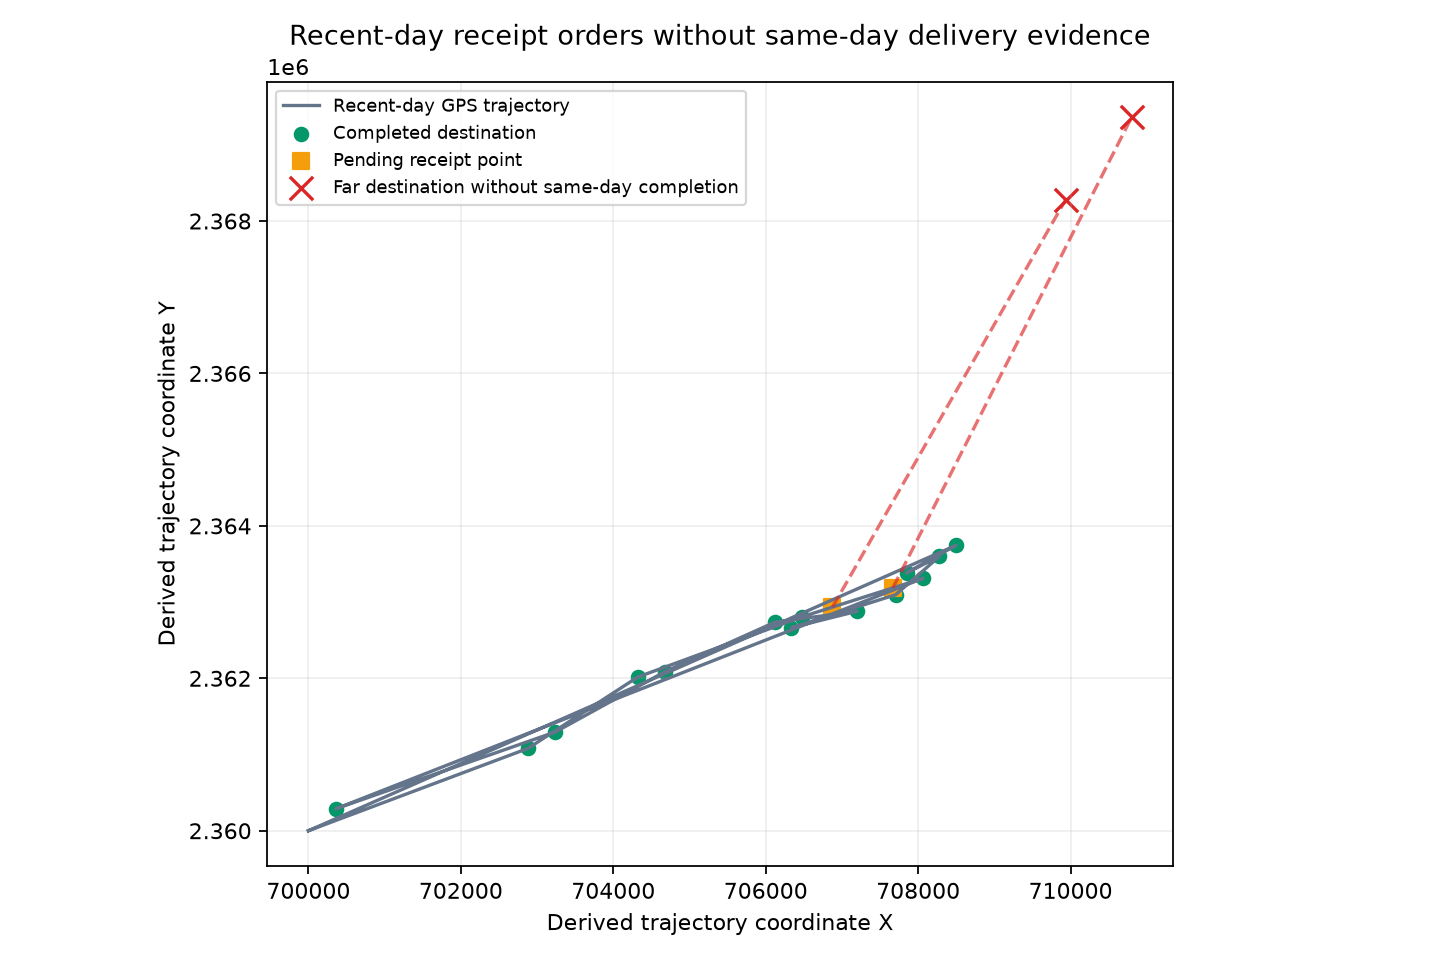

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); d['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])
q = d[(d['ds'] == d['ds'].max()) & d['receipt_time'].notna() & d['sign_time'].isna()]
t = user_df[user_df['ds'] == d['ds'].max()].copy()
plt.figure(figsize=(9, 6)); plt.plot(t['lng'], t['lat'], color='gray', label='Recent-day GPS trajectory')
plt.scatter(q['receipt_lng'], q['receipt_lat'], marker='s', c='orange', label='Receipt point')
plt.scatter(q['poi_lng'], q['poi_lat'], marker='x', c='red', s=100, label='No same-day completion')
for _, row in q.iterrows(): plt.plot([row['receipt_lng'], row['poi_lng']], [row['receipt_lat'], row['poi_lat']], '--', color='red')
plt.xlabel('Coordinate X'); plt.ylabel('Coordinate Y'); plt.axis('equal'); plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/recent_pending_receipt_orders.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "exception",
  "insight": "On the recent workday, two receipt-bearing orders have far destinations but no same-day delivery completion or matching trajectory evidence, unlike the completed receipt-bearing orders.",
  "insight_value": {
    "recent_pending_receipt_orders": 2,
    "same_day_completion_missing": true
  },
  "plot": {
    "plot_type": "trajectory_exception_map",
    "title": "Recent Receipt Orders without Same-Day Completion",
    "file": "visualizations/recent_pending_receipt_orders.png",
    "description": "Far destinations without same-day completion are shown as red crosses, separated from the recent-day GPS trajectory."
  },
  "question": "Among recent-day orders with receipt events, are there far destinations that lack same-day completion and matching trajectory evidence?",
  "actionable_insight": "Compare receipt-bearing orders with missing completion events and inspect whether their destinations fall outside the observed day route.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); d['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])\nq = d[(d['ds'] == d['ds'].max()) & d['receipt_time'].notna() & d['sign_time'].isna()]\nt = user_df[user_df['ds'] == d['ds'].max()].copy()\nplt.figure(figsize=(9, 6)); plt.plot(t['lng'], t['lat'], color='gray', label='Recent-day GPS trajectory')\nplt.scatter(q['receipt_lng'], q['receipt_lat'], marker='s', c='orange', label='Receipt point')\nplt.scatter(q['poi_lng'], q['poi_lat'], marker='x', c='red', s=100, label='No same-day completion')\nfor _, row in q.iterrows(): plt.plot([row['receipt_lng'], row['poi_lng']], [row['receipt_lat'], row['poi_lat']], '--', color='red')\nplt.xlabel('Coordinate X'); plt.ylabel('Coordinate Y'); plt.axis('equal'); plt.legend(); plt.show()",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "completion_time",
    "destination_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### Summary of Findings (Flag 4)

The courier's observed behavior differs between the first and recent workdays: the first day follows a nearest-first pattern but covers a longer and slower route with no receipt events, whereas the recent day uses a more compact and faster route, makes several non-nearest-first choices, includes receipt events for half of its orders, and leaves two far receipt-bearing destinations without same-day completion evidence.